### Amin Maki (Maky)
- 405551014

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

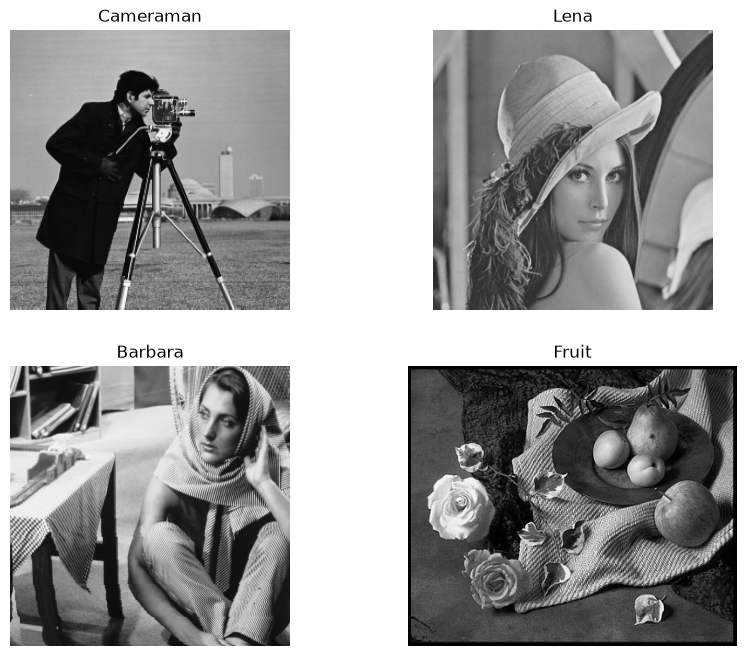

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

base_dir = "Pic"

cameraman = cv2.imread(os.path.join(base_dir, 'cameraman.tif'), cv2.IMREAD_GRAYSCALE)
lena      = cv2.imread(os.path.join(base_dir, 'lena.bmp'), cv2.IMREAD_GRAYSCALE)
barbara   = cv2.imread(os.path.join(base_dir, 'barbara.bmp'), cv2.IMREAD_GRAYSCALE)
fruit_color = cv2.imread(os.path.join(base_dir, 'fruit.jpg'))

# To prevent any potential exception (￣ー￣)ｂ
if cameraman is None: print("Error: cameraman.tif not found")
if lena is None: print("Error: lena.bmp not found")
if barbara is None: print("Error: barbara.bmp not found")
if fruit_color is None: print("Error: fruit.jpg not found")

if any(img is None for img in [cameraman, lena, barbara, fruit_color]):
    raise FileNotFoundError("One or more images failed to load. Check the file paths.")

# Convert color image to grayscale
fruit = cv2.cvtColor(fruit_color, cv2.COLOR_BGR2GRAY)

# Display images
images = [cameraman, lena, barbara, fruit]
titles = ['Cameraman', 'Lena', 'Barbara', 'Fruit']

plt.figure(figsize=(10, 8))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i], fontsize=12)
    plt.axis('off')
plt.show()


In [3]:
image_dict = {
    "Cameraman": cameraman,
    "Lena": lena,
    "Barbara": barbara,
    "Fruit (Gray)": fruit
}

print(f"{'Image Name':<15} | {'Shape (H, W)':<14} | {'Dtype':<8} | {'Min':<5} | {'Max':<5} | {'Mean':<10}")
print("-" * 70)

for name, img in image_dict.items():
    img_shape = str(img.shape)
    img_dtype = str(img.dtype)
    img_min   = np.min(img)
    img_max   = np.max(img)
    img_mean  = np.mean(img)
    
    print(f"{name:<15} | {img_shape:<14} | {img_dtype:<8} | {img_min:<5} | {img_max:<5} | {img_mean:<10.2f}")


Image Name      | Shape (H, W)   | Dtype    | Min   | Max   | Mean      
----------------------------------------------------------------------
Cameraman       | (256, 256)     | uint8    | 7     | 253   | 118.72    
Lena            | (512, 512)     | uint8    | 34    | 247   | 125.16    
Barbara         | (512, 512)     | uint8    | 7     | 250   | 126.59    
Fruit (Gray)    | (321, 377)     | uint8    | 0     | 254   | 79.87     


In [4]:
# Image dictionary for extracting specifications
image_dict = {
    "Cameraman": cameraman,
    "Lena": lena,
    "Barbara": barbara,
    "Fruit (Gray)": fruit
}

print(f"{'Image Name':<15} | {'Shape (H, W)':<14} | {'Dtype':<8} | {'Min':<5} | {'Max':<5} | {'Mean':<10}")
print("-" * 70)

for name, img in image_dict.items():
    img_shape = str(img.shape)
    img_dtype = str(img.dtype)
    img_min   = np.min(img)
    img_max   = np.max(img)
    img_mean  = np.mean(img)
    
    print(f"{name:<15} | {img_shape:<14} | {img_dtype:<8} | {img_min:<5} | {img_max:<5} | {img_mean:<10.2f}")


Image Name      | Shape (H, W)   | Dtype    | Min   | Max   | Mean      
----------------------------------------------------------------------
Cameraman       | (256, 256)     | uint8    | 7     | 253   | 118.72    
Lena            | (512, 512)     | uint8    | 34    | 247   | 125.16    
Barbara         | (512, 512)     | uint8    | 7     | 250   | 126.59    
Fruit (Gray)    | (321, 377)     | uint8    | 0     | 254   | 79.87     


### توضیحات و تحلیل بخش اول: بارگذاری تصاویر و استخراج مشخصات پایه

#### ۱. شرح کدها و خروجی‌ها:
* **نحوه بارگذاری:** سه تصویر `cameraman.tif`، `lena.bmp` و `barbara.bmp` با استفاده از پرچم `cv2.IMREAD_GRAYSCALE` مستقیماً به صورت ماتریس‌های دوبعدی تک‌کاناله (سطح خاکستری) بارگذاری شدند. تصویر `fruit.jpg` ابتدا به صورت رنگی (۳ کاناله BGR) خوانده شد و سپس با دستور `cv2.cvtColor(fruit_color, cv2.COLOR_BGR2GRAY)` به تصویر سطح خاکستری تبدیل گردید.
* **مشخصات آماری و ساختاری:**
  * **ابعاد (`shape`):** نشان‌دهنده تعداد سطرها (ارتفاع $H$) و ستون‌ها (عرض $W$) در ماتریس دوبعدی تصویر است (مثلاً $256 \times 256$ برای Cameraman و $512 \times 512$ برای Lena و Barbara).
  * **نوع داده (`dtype`):** تمام تصاویر از نوع `uint8` (عدد صحیح بدون علامت ۸ بیتی) هستند که مقادیر شدت روشنایی در بازه استاندارد $[0, 255]$ را پشتیبانی می‌کند.
  * **کمینه (`min`)، بیشینه (`max`) و میانگین (`mean`):** بازه پویایی (Dynamic Range) و سطح روشنایی کلی هر تصویر را مشخص می‌کنند. تصاویر Lena و Barbara با میانگین حدود ۱۲۵ روشنایی متعادلی دارند، در حالی که تصویر Fruit میانگین پایین‌تری داشته و دارای نواحی تیره‌تر بیشتری است.

---

#### ۲. پاسخ به سؤال: چرا تبدیل تصویر `fruit.jpg` به سطح خاکستری برای انجام عملیات این آزمایش ضروری است؟
1. **کاهش ابعاد و یکسان‌سازی ساختار ماتریس‌ها:** تصویر رنگی `fruit.jpg` دارای ۳ کانال رنگی (آبی، سبز و قرمز - BGR) بوده و ماتریس آن سه‌بعدی با ابعاد $(H, W, 3)$ است، در حالی که سه تصویر دیگر تک‌کاناله و دوبعدی با ابعاد $(H, W)$ هستند. برای انجام عملیات مقایسه‌ای و به‌ویژه عملیات حسابی بین تصاویر (جمع و تفریق در بخش‌های بعدی)، تمام تصاویر باید ساختار ابعادی و تعداد کانال‌های یکسانی داشته باشند.
2. **تمرکز بر شدت روشنایی (Intensity):** هدف این آزمایش بررسی مفاهیم پایه‌ای پردازش تصویر نظیر تغییر روشنایی و کنتراست، نمونه‌برداری مکانی و کوانتیزاسیون سطوح روشنایی $I(x,y)$ است. تبدیل تصویر رنگی به سطح خاکستری (از طریق ترکیب خطی استاندارد کانال‌ها: $Y = 0.299R + 0.587G + 0.114B$) اطلاعات فام و اشباع رنگ (Chrominance) را حذف کرده و تنها اطلاعات روشنایی (Luminance) را در یک کانال مجزا در اختیار ما قرار می‌دهد.
3. **جلوگیری از تغییر رنگ ناخواسته (Color Distortion):** اعمال مستقیم برخی تبدیل‌های نقطه‌ای یا کوانتیزاسیون به صورت جداگانه روی ۳ کانال رنگی می‌تواند نسبت بین کانال‌های R، G و B را برهم زده و رنگ‌های کاذب ایجاد کند؛ در حالی که در حالت خاکستری اثر خالص الگوریتم بر سطوح روشنایی به دقت قابل مشاهده و تحلیل است.


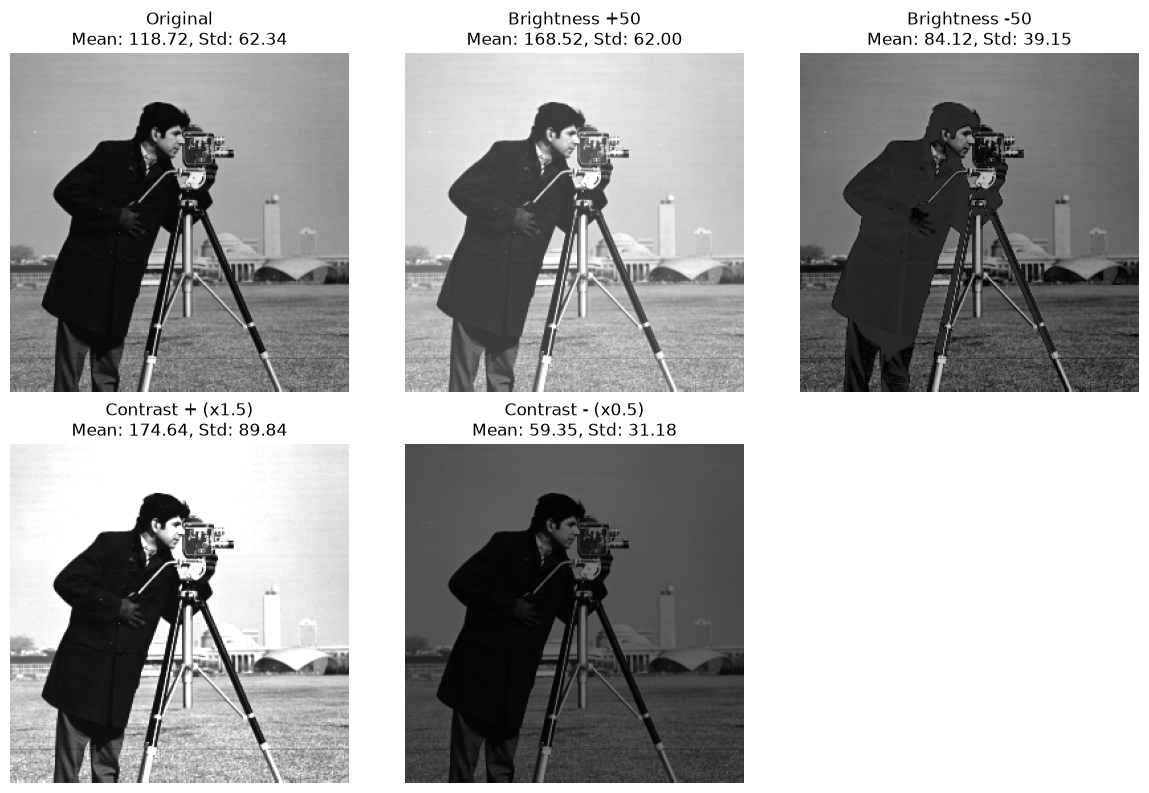

In [5]:
# Helper function for conversion and display
def adjust_brightness_contrast(img, alpha, beta):
    # g(x,y) = alpha * f(x,y) + beta
    # alpha: Contrast (gain)
    # beta: Brightness (bias)
    adjusted = cv2.convertScaleAbs(img, alpha=alpha, beta=beta)
    return adjusted

# Settings for 4 question modes
params = [
    (1.0, 50, "Brightness +50"),   # Increase brightness
    (1.0, -50, "Brightness -50"),  # Decrease brightness
    (1.5, 0, "Contrast + (x1.5)"), # Increase contrast
    (0.5, 0, "Contrast - (x0.5)")  # Decrease contrast
]

plt.figure(figsize=(12, 8))
# Original image
plt.subplot(2, 3, 1)
plt.imshow(cameraman, cmap='gray', vmin=0, vmax=255)
plt.title("Original\nMean: {:.2f}, Std: {:.2f}".format(np.mean(cameraman), np.std(cameraman)))
plt.axis('off')

# Modified images
for i, (a, b, title) in enumerate(params):
    res = adjust_brightness_contrast(cameraman, a, b)
    plt.subplot(2, 3, i + 2)
    plt.imshow(res, cmap='gray', vmin=0, vmax=255)
    plt.title(f"{title}\nMean: {np.mean(res):.2f}, Std: {np.std(res):.2f}")
    plt.axis('off')

plt.tight_layout()
plt.show()


### تحلیل نتایج فاز ۲: تغییر روشنایی و کنتراست

#### ۱. تفاوت تغییر روشنایی و کنتراست:
* **تغییر روشنایی (Brightness):** با اضافه کردن مقدار ثابت $b$ به تمام پیکسل‌ها ($f(x,y) + b$)، هیستوگرام تصویر به سمت راست (روشن‌تر) یا چپ (تیره‌تر) شیفت پیدا می‌کند. این کار باعث تغییر **میانگین (Mean)** روشنایی تصویر می‌شود اما پراکندگی پیکسل‌ها (شکل هیستوگرام) تغییری نمی‌کند.
* **تغییر کنتراست (Contrast):** با ضرب پیکسل‌ها در ضریب $a$ ($a \cdot f(x,y)$)، هیستوگرام حول مقدار میانگین کشیده یا فشرده می‌شود. این کار باعث تغییر **انحراف معیار (Standard Deviation)** می‌شود. ضریب $a>1$ باعث بازتر شدن بازه روشنایی و $a<1$ باعث فشرده شدن آن می‌گردد.

#### ۲. چرا افزایش کنتراست ممکن است باعث از دست رفتن جزئیات شود؟
با افزایش ضریب $a$، مقادیرِ پیکسل‌هایی که در حالت اصلی در نواحی پرنور (بالای ۲۵۵) یا بسیار تیره (زیر ۰) قرار دارند، از محدوده مجاز `uint8` خارج می‌شوند. عملیات Clipping (یا اشباع) این مقادیر را به ۲۵۵ (سفید مطلق) یا ۰ (سیاه مطلق) می‌چسباند. در نتیجه، تفاوت شدت روشنایی در نواحی خیلی روشن یا خیلی تیره از بین رفته و جزئیات در این نواحی دچار پدیده‌ی "اشباع" یا "Clipping" می‌شوند.

#### ۳. آیا افزایش روشنایی همیشه کیفیت تصویر را بهتر می‌کند؟
خیر. همان‌طور که در تصویر حاصل از `Brightness +50` دیده می‌شود، افزایش بیش از حد روشنایی باعث می‌شود پیکسل‌های با شدت متوسط به سمت ۲۵۵ حرکت کرده و در نواحی روشن، "سفید‌شدگی" یا Wash-out رخ دهد. این کار باعث کاهش کنتراست محلی و از بین رفتن جزئیات در نواحی روشن می‌شود، به همین دلیل در شرایط نوری مناسب، بهترین کیفیت زمانی است که بازه هیستوگرام تا حد امکان تمام بازه $[0, 255]$ را بپوشاند بدون اینکه اشباع شود.


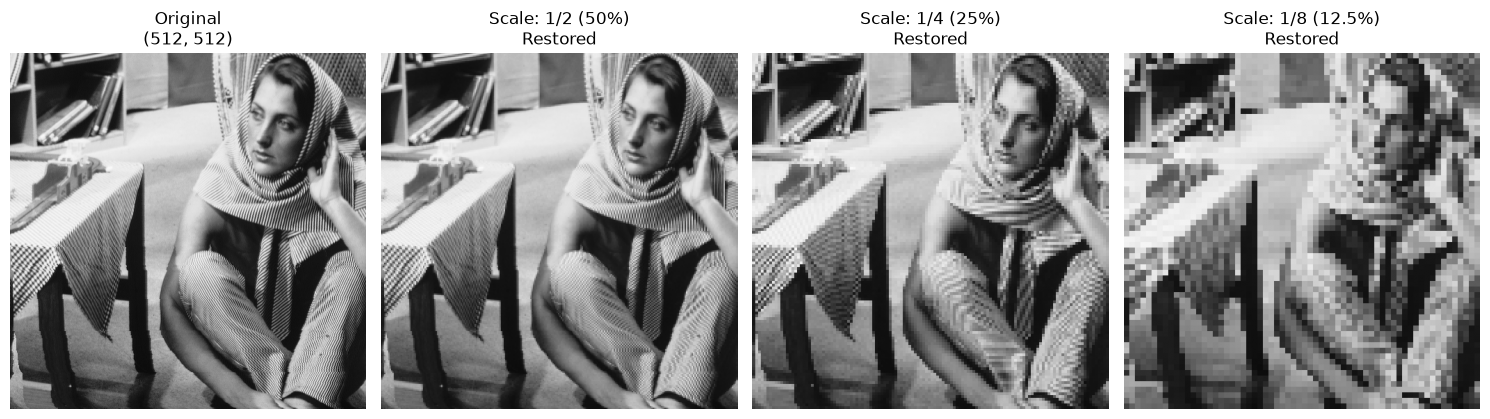

Scale        | Shape (H, W)    | Total Pixels
---------------------------------------------
Original     | (512, 512)      | 262144
1/2 (50%)    | (256, 256)      | 65536
1/4 (25%)    | (128, 128)      | 16384
1/8 (12.5%)  | (64, 64)        | 4096


In [6]:
# Function to downsample and upsample for comparison
def resize_and_analyze(img, scale_factor):
    # Resize down
    width = int(img.shape[1] * scale_factor)
    height = int(img.shape[0] * scale_factor)
    resized = cv2.resize(img, (width, height), interpolation=cv2.INTER_LINEAR)
    
    # Resize back up to original size for visual comparison
    restored = cv2.resize(resized, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
    return resized, restored

scales = [0.5, 0.25, 0.125]
titles = ['1/2 (50%)', '1/4 (25%)', '1/8 (12.5%)']

plt.figure(figsize=(15, 5))
# Show original for comparison
plt.subplot(1, 4, 1)
plt.imshow(barbara, cmap='gray', vmin=0, vmax=255)
plt.title(f"Original\n{barbara.shape}")
plt.axis('off')

# Show downsampled and restored images
for i, (scale, title) in enumerate(zip(scales, titles)):
    _, restored = resize_and_analyze(barbara, scale)
    plt.subplot(1, 4, i + 2)
    plt.imshow(restored, cmap='gray', vmin=0, vmax=255)
    plt.title(f"Scale: {title}\nRestored")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Report dimensions and pixel counts
print(f"{'Scale':<12} | {'Shape (H, W)':<15} | {'Total Pixels'}")
print("-" * 45)
print(f"{'Original':<12} | {str(barbara.shape):<15} | {barbara.size}")
for scale, title in zip(scales, titles):
    r, _ = resize_and_analyze(barbara, scale)
    print(f"{title:<12} | {str(r.shape):<15} | {r.size}")


### تحلیل نتایج فاز ۳: کاهش وضوح مکانی (Spatial Resolution)

#### ۱. مقایسه بصری و تحلیل کیفیت:
با کاهش وضوح (Downsampling)، تعداد پیکسل‌ها به شدت کاهش می‌یابد. در مقیاس‌های کوچک‌تر (مثلاً ۱/۸)، بافت‌های ریز تصویر (مانند خطوط لباس Barbara) کاملاً از بین می‌روند و لبه‌ها دچار پدیده "پله‌پله شدن" (Aliasing/Pixelation) می‌شوند. 

#### ۲. پاسخ به سؤالات تشریحی:
* **اثر کاهش وضوح بر جزئیات:** کاهش وضوح مکانی در واقع به معنای حذف **فرکانس‌های بالا** (جزئیات ریز و لبه‌های تیز) از تصویر است. هرچه وضوح کمتر شود، اطلاعات جزئیاتی تصویر فدای کاهش حجم داده‌ها می‌شود.
* **آیا بزرگ‌نمایی مجدد اطلاعات ازدست‌رفته را بازیابی می‌کند؟** خیر. هنگام کاهش ابعاد، اطلاعات فرکانس بالای تصویر برای همیشه حذف می‌شوند. بزرگ‌نمایی مجدد (Upsampling) تنها با درون‌یابی (Interpolation) تلاش می‌کند فضای خالی بین پیکسل‌ها را حدس بزند که نتیجه آن تاری (Blurriness) یا شطرنجی شدن (در صورت استفاده از روش Nearest Neighbor) است، نه بازگشت به جزئیات اصلی.
* **چرا کاهش وضوح تشخیص اشیای کوچک را دشوار می‌کند؟** زمانی که یک شیء کوچک در ابعاد چند پیکسل محدود شود، تفکیک مرزهای آن از پس‌زمینه (Contour) غیرممکن می‌گردد. در واقع آن شیء در میانگین‌گیری پیکسل‌ها با پس‌زمینه ادغام شده و ساختار هندسی خود را از دست می‌دهد.


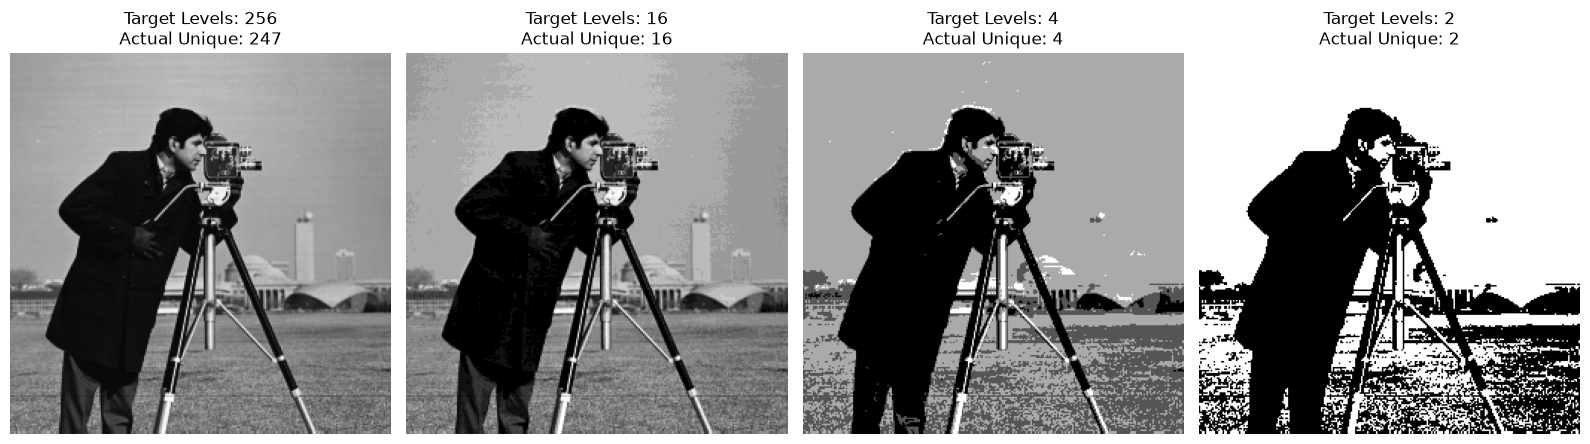

In [7]:
# Function for Uniform Quantization
def quantize_image(img, L):
    """
    Reduces the number of intensity levels to L.
    """
    # Size of each quantization step
    step = 256 / L
    
    # Map pixels to the new reduced levels (0 to L-1)
    quantized_idx = (img / step).astype(np.uint8)
    
    # Scale back to 0-255 range for proper display
    quantized_img = (quantized_idx * (255 / (L - 1))).astype(np.uint8)
    
    return quantized_img

# Levels to test
levels_list = [256, 16, 4, 2]

plt.figure(figsize=(16, 5))
for i, L in enumerate(levels_list):
    if L == 256:
        q_img = cameraman.copy() # Original (already 256 levels)
    else:
        q_img = quantize_image(cameraman, L)
        
    plt.subplot(1, 4, i + 1)
    plt.imshow(q_img, cmap='gray', vmin=0, vmax=255)
    
    # Count actual unique intensity levels used in the image
    unique_levels = len(np.unique(q_img))
    
    plt.title(f"Target Levels: {L}\nActual Unique: {unique_levels}")
    plt.axis('off')

plt.tight_layout()
plt.show()


### تحلیل نتایج فاز ۴: کاهش تعداد سطوح شدت روشنایی (Intensity Quantization)

#### ۱. تفاوت کوانتیزه کردن با کاهش وضوح مکانی:
* **کاهش وضوح مکانی (Spatial Downsampling):** روی محورهای $x$ و $y$ (مختصات پیکسل‌ها) اثر می‌گذارد و تعداد کل پیکسل‌های تشکیل‌دهنده‌ی شبکه تصویر را کم می‌کند (حذف اطلاعات فرکانس بالا و ایجاد پله‌پله شدن لبه‌ها).
* **کوانتیزه کردن (Quantization):** ابعاد شبکه تغییر نمی‌کند، بلکه روی **دامنه یا شدت روشنایی $I(x,y)$** اثر می‌گذارد و تعداد پله‌های روشنایی مجاز (عمق بیت) را کاهش می‌دهد (حذف ظرافت طیف رنگی/خاکستری).

#### ۲. چرا کاهش تعداد سطوح باعث ایجاد نوارهای قابل مشاهده می‌شود؟
این پدیده که به آن **False Contouring** (یا Posterization) می‌گویند، به این دلیل رخ می‌دهد که در نواحی با گرادیان نوری ملایم و نرم (تغییرات تدریجی روشنایی)، مقادیر پِیوسته‌تر به یک سطح یکسان (محدود) گرد می‌شوند. وقتی مقدار روشنایی به آستانه‌ی سطح بعدی می‌رسد، یک پرش ناگهانی (پله‌ای) در شدت نوری رخ می‌دهد که چشم انسان آن را به صورت مرزها و نوارهای مصنوعی درک می‌کند.

#### ۳. کدام تصویر برای مشاهده اثر کوانتیزه کردن مناسب‌تر است؟ دلیل خود را بیان کنید.
تصویر `Cameraman` (مخصوصاً در ناحیه آسمان) یا تصویر `Lena` (در نواحی پوست و شانه) انتخاب‌های بسیار بهتری هستند. 
**دلیل:** پدیده False Contouring در مناطقی که شدت روشنایی به صورت نرم و تدریجی تغییر می‌کند (Smooth Gradients) به وضوح خود را نشان می‌دهد. در تصاویری که بافت (Texture) شلوغ و فرکانس بالایی دارند (مانند بافت لباس در تصویر `Barbara`)، خطای کوانتیزاسیون در میان تغییرات سریع روشنایی پنهان شده و نوارهای کاذب به سادگی به چشم نمی‌آیند.


Before resizing -> img1: (256, 256), img2: (512, 512)
After resizing  -> img1: (512, 512), img2: (512, 512)


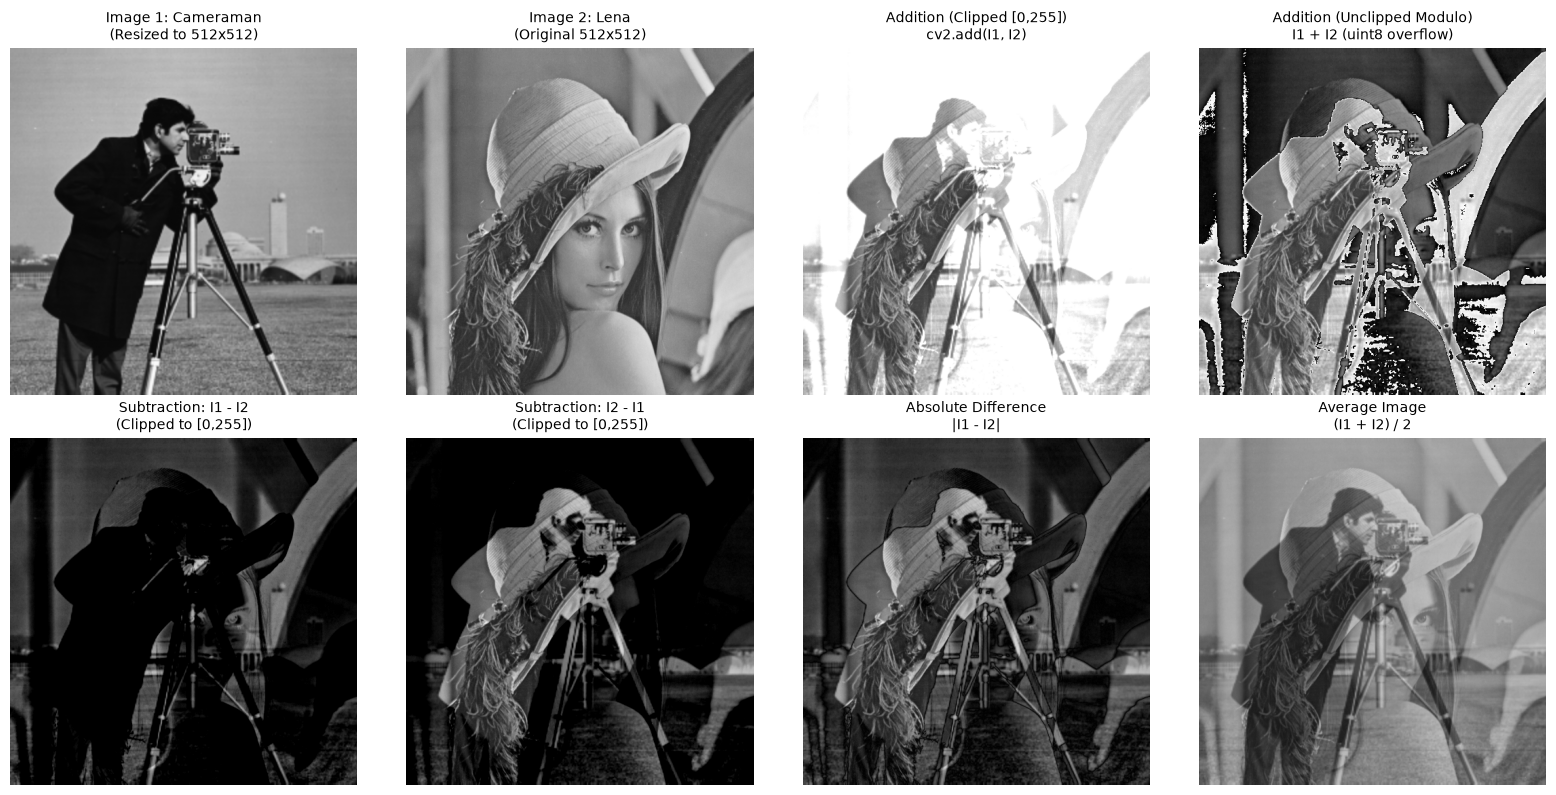

In [8]:
# Select two grayscale images with different initial sizes
img1 = cameraman.copy()  # Shape: (256, 256)
img2 = lena.copy()       # Shape: (512, 512)

print(f"Before resizing -> img1: {img1.shape}, img2: {img2.shape}")

# Ensure both images have the same dimensions using OpenCV
if img1.shape != img2.shape:
    # Resize img1 to match img2 dimensions (width, height)
    img1 = cv2.resize(img1, (img2.shape[1], img2.shape[0]), interpolation=cv2.INTER_LINEAR)

print(f"After resizing  -> img1: {img1.shape}, img2: {img2.shape}")

# 1. Image Addition
# Clipped addition to [0, 255] (Saturation arithmetic)
add_clipped = cv2.add(img1, img2)
# Unclipped addition (Modulo 256 overflow in uint8) to observe clipping effect
add_unclipped = img1 + img2

# 2. Image Subtraction (Clipped to [0, 255])
sub_1_2 = cv2.subtract(img1, img2)  # max(img1 - img2, 0)
sub_2_1 = cv2.subtract(img2, img1)  # max(img2 - img1, 0)
abs_diff = cv2.absdiff(img1, img2)  # |img1 - img2|

# 3. Image Averaging
avg_img = ((img1.astype(np.float32) + img2.astype(np.float32)) / 2).astype(np.uint8)

# Plot original images and arithmetic results side by side
results = [
    (img1, "Image 1: Cameraman\n(Resized to 512x512)"),
    (img2, "Image 2: Lena\n(Original 512x512)"),
    (add_clipped, "Addition (Clipped [0,255])\ncv2.add(I1, I2)"),
    (add_unclipped, "Addition (Unclipped Modulo)\nI1 + I2 (uint8 overflow)"),
    (sub_1_2, "Subtraction: I1 - I2\n(Clipped to [0,255])"),
    (sub_2_1, "Subtraction: I2 - I1\n(Clipped to [0,255])"),
    (abs_diff, "Absolute Difference\n|I1 - I2|"),
    (avg_img, "Average Image\n(I1 + I2) / 2")
]

plt.figure(figsize=(16, 8))
for idx, (res_img, title) in enumerate(results):
    plt.subplot(2, 4, idx + 1)
    plt.imshow(res_img, cmap='gray', vmin=0, vmax=255)
    plt.title(title, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()


### تحلیل نتایج فاز ۵: عملیات حسابی روی تصاویر

#### بررسی اثر محدود کردن مقادیر به بازه $[0, 255]$ (Clipping vs. Modulo):
در تصاویر ۸ بیتی (`uint8`)، بازه مجاز مقادیر پیکسل‌ها بین $0$ تا $255$ است. هنگام انجام عملیات جمع یا تفریق، مقادیر حاصل می‌توانند از این بازه خارج شوند (بازه $[-255, 510]$):
* **بدون محدودسازی (جمع/تفریق پیش‌فرض NumPy روی `uint8`):** محاسبات به صورت پیمانه‌ای (Modulo 256) انجام می‌شود. یعنی اگر مجموع دو پیکسل $300$ شود، به دلیل سرریز (Overflow) مقدار $300 - 256 = 44$ (تیره) ثبت می‌گردد که باعث ایجاد لکه‌های سیاه کاذب در نواحی روشن تصویر جمع بدون محدودسازی شده است.
* **با محدودسازی (Clipping در `cv2.add` و `cv2.subtract` یا `np.clip`):** مقادیر بالای $255$ روی عدد $255$ (سفید) و مقادیر منفی روی عدد $0$ (سیاه) قفل می‌شوند که از نظر بصری رفتار طبیعی‌تری ایجاد می‌کند.

#### پاسخ به سؤالات تشریحی:
1. **چرا جمع دو تصویر ممکن است موجب اشباع شدت روشنایی شود؟**
   چون شدت روشنایی هر یک از دو تصویر ورودی در بازه $[0, 255]$ قرار دارد و مجموع متناظر پیکسل‌ها می‌تواند تا $510$ افزایش یابد. با اعمال محدودسازی به سقف $255$، تمام پیکسل‌هایی که مجموعشان بیش از $255$ شود به رنگ سفید خالص ($255$) بریده می‌شوند (پدیده اشباع یا Saturation) و جزئیات نواحی روشن از دست می‌رود. (در مقابل، در **میانگین‌گیری** به دلیل تقسیم مجموع بر $2$، خروجی همواره در بازه $[0, 255]$ باقی می‌ماند و دچار اشباع نمی‌شود).

2. **چرا تفریق تصویر اول از دوم ($I_1 - I_2$) با تفریق تصویر دوم از اول ($I_2 - I_1$) یکسان نیست؟**
   عملگر تفریق خاصیت جابه‌جایی ندارد ($I_1 - I_2 = -(I_2 - I_1)$). هنگامی که مقادیر به بازه $[0, 255]$ محدود (Clip) می‌شوند:
   * در $I_1 - I_2$، تمام پیکسل‌هایی که در آن‌ها $I_1 < I_2$ است منفی شده و به $0$ (سیاه) تبدیل می‌شوند و فقط نواحی‌ای که تصویر اول روشن‌تر از تصویر دوم است (مثل آسمان روشن Cameraman) باقی می‌مانند.
   * برعکس، در $I_2 - I_1$، نواحی‌ای که $I_2 < I_1$ است صفر می‌شوند و فقط بخش‌هایی که تصویر دوم روشن‌تر از تصویر اول است (مثل کلاه و صورت Lena در جایی که کت سیاه Cameraman قرار داشته) دیده می‌شوند.

3. **اختلاف دو تصویر در چه کاربردهایی می‌تواند مفید باشد؟**
   * **تشخیص حرکت (Motion Detection) و حذف پس‌زمینه (Background Subtraction):** با کم کردن فریم فعلی دوربین از فریم پس‌زمینه ثابت، بخش‌های ثابت صفر (سیاه) شده و فقط اشیای متحرک مشخص می‌شوند.
   * **کنترل کیفیت و بازرسی صنعتی (Industrial Defect Inspection):** مقایسه تصویر یک برد الکترونیکی (PCB) یا قطعه تولیدشده با تصویر مرجعِ سالم برای یافتن قطعات جاافتاده یا نقایص ظاهری.
   * **تصویربرداری پزشکی (مثل آنژیوگرافی تفاضلی دیجیتال - DSA) و سنجش از دور:** کم کردن تصاویر قبل و بعد از تزریق ماده حاجب برای نمایش خالص رگ‌های خونی، یا مقایسه تصاویر ماهواره‌ای در دو زمان مختلف برای تشخیص تغییرات زمین (Change Detection).
